In [1]:
print("Hello, Benford's Law!")

Hello, Benford's Law!


In [2]:
!uv add pandas
import pandas as pd

Resolved 73 packages in 8ms
Checked 71 packages in 16ms


In [3]:
!uv add matplotlib
import matplotlib.pyplot as plt

Resolved 73 packages in 4ms
Checked 71 packages in 1ms


In [4]:
import os
import numpy as np

In [5]:
digitos = range(1, 10)
probs_benford = {}
for digito in digitos:
    probs_benford[digito] = np.log10(1 + 1 / digito)
# print(probs_benford)
benford = pd.Series(probs_benford, name="Benford Esperado")
display(benford)

1    0.301030
2    0.176091
3    0.124939
4    0.096910
5    0.079181
6    0.066947
7    0.057992
8    0.051153
9    0.045757
Name: Benford Esperado, dtype: float64

In [6]:
N = 10_000

r = np.random.RandomState(seed=42)
valores = r.lognormal(mean=5.0, sigma=1.5, size=N)
print(valores)

[312.64589665 120.61498716 392.1062336  ...  51.52282504 312.20135852
 390.17005413]


In [13]:
df = pd.DataFrame({"valor": valores})
display(df)

,valor
0,312.645897
1,120.614987
2,392.106234
3,1457.597461
4,104.456419
...,...
9995,1044.875579
9996,7.407423
9997,51.522825
9998,312.201359


In [14]:
# df["valor"].iloc[0]
# abs(df["valor"].iloc[0])
# str(abs(df["valor"].iloc[0]))
# str(abs(df["valor"].iloc[0])).lstrip("0")
# str(abs(df["valor"].iloc[0])).lstrip("0").replace(".", "")
# str(abs(df["valor"].iloc[0])).lstrip("0").replace(".", "")[0]
print(str(abs(df["valor"].iloc[0])).lstrip("0").replace(".", "")[0])
print(str(abs(0.21)).lstrip("0").replace(".", "")[0])
print(str(abs(-0.74)).lstrip("0").replace(".", "")[0])

3
2
7


In [15]:
def primeiro_digito(x: float) -> int:
    return int(str(abs(x)).lstrip("0").replace(".", "")[0])
print(primeiro_digito(-7.5))
print(primeiro_digito(0.63))

7
6


In [16]:
df["primeiro_digito"] = df["valor"].apply(primeiro_digito)
display(df)

,valor,primeiro_digito
0,312.645897,3
1,120.614987,1
2,392.106234,3
3,1457.597461,1
4,104.456419,1
...,...,...
9995,1044.875579,1
9996,7.407423,7
9997,51.522825,5
9998,312.201359,3


In [17]:
# display(df["primeiro_digito"].value_counts(normalize=True))
freq_obs = df["primeiro_digito"].value_counts(normalize=True)
freq_obs.name = "Observado"
display(freq_obs)

primeiro_digito
1    0.3049
2    0.1737
3    0.1256
4    0.0957
5    0.0770
6    0.0681
7    0.0584
8    0.0527
9    0.0439
Name: Observado, dtype: float64

In [18]:
df_final = pd.DataFrame(
    {"Benford (%)": benford * 100,
     "Observado (%)": freq_obs * 100,
     "Diferença (%)": (freq_obs - benford) * 100,
     "Observado": (freq_obs * N),
     "Esperado": (benford * N)
    }
)
display(df_final.round(2))

,Benford (%),Observado (%),Diferença (%),Observado,Esperado
1,30.10,30.49,0.39,3049.0,3010.30
2,17.61,17.37,-0.24,1737.0,1760.91
3,12.49,12.56,0.07,1256.0,1249.39
4,9.69,9.57,-0.12,957.0,969.10
5,7.92,7.70,-0.22,770.0,791.81
6,6.69,6.81,0.12,681.0,669.47
7,5.80,5.84,0.04,584.0,579.92
8,5.12,5.27,0.15,527.0,511.53
9,4.58,4.39,-0.19,439.0,457.57


In [19]:
df_final["Diferença"] = df_final["Esperado"] - df_final["Observado"]
df_final["QQ"] = df_final["Diferença"] ** 2 / df_final["Esperado"]
display(df_final)

,Benford (%),Observado (%),Diferença (%),Observado,Esperado,Diferença,QQ
1,30.103000,30.49,0.387000,3049.0,3010.299957,-38.700043,0.497523
2,17.609126,17.37,-0.239126,1737.0,1760.912591,23.912591,0.324725
3,12.493874,12.56,0.066126,1256.0,1249.387366,-6.612634,0.034999
4,9.691001,9.57,-0.121001,957.0,969.100130,12.100130,0.151082
5,7.918125,7.70,-0.218125,770.0,791.812460,21.812460,0.600879
6,6.694679,6.81,0.115321,681.0,669.467896,-11.532104,0.198649
7,5.799195,5.84,0.040805,584.0,579.919470,-4.080530,0.028712
8,5.115252,5.27,0.154748,527.0,511.525224,-15.474776,0.468146
9,4.575749,4.39,-0.185749,439.0,457.574906,18.574906,0.754034


In [20]:
df_final["QQ"].sum()

np.float64(3.0587490619796593)

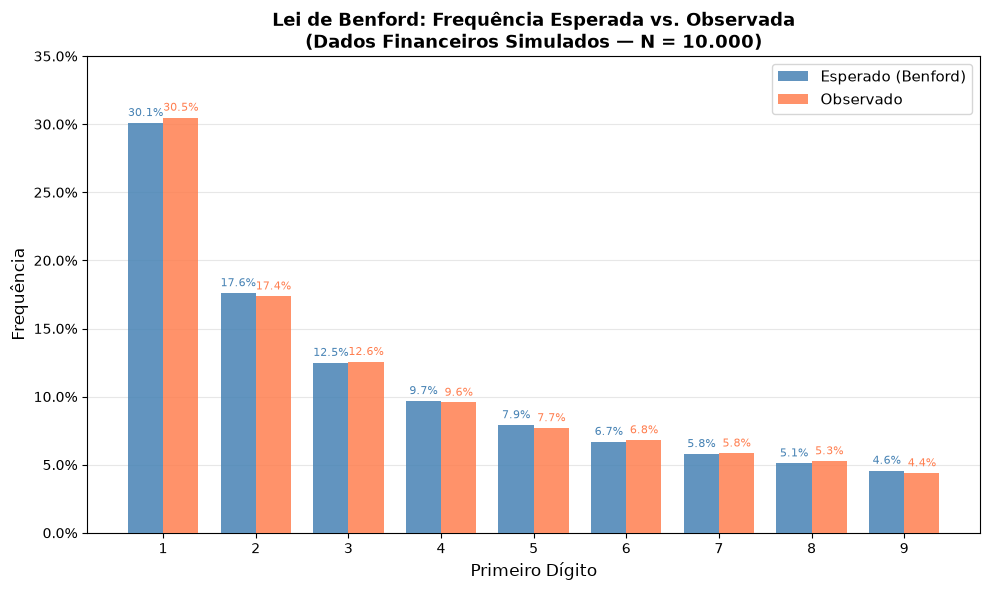

In [21]:
import matplotlib.ticker as mtick

x = np.arange(1, 10)
largura = 0.38

fig, eixo = plt.subplots(figsize=(10, 6))

barras_esp = eixo.bar(x - largura / 2, benford.values * 100, largura,
                      label="Esperado (Benford)", color="steelblue", alpha=0.85, zorder=3)
barras_obs = eixo.bar(x + largura / 2, freq_obs.values * 100, largura,
                      label="Observado", color="coral", alpha=0.85, zorder=3)

# Rótulos sobre as barras
for barra in barras_esp:
    eixo.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.3,
              f"{barra.get_height():.1f}%", ha="center", va="bottom", fontsize=8, color="steelblue")
for barra in barras_obs:
    eixo.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.3,
              f"{barra.get_height():.1f}%", ha="center", va="bottom", fontsize=8, color="coral")

eixo.set_xlabel("Primeiro Dígito", fontsize=12)
eixo.set_ylabel("Frequência", fontsize=12)
eixo.set_title("Lei de Benford: Frequência Esperada vs. Observada\n(Dados Financeiros Simulados — N = 10.000)",
               fontsize=13, fontweight="bold")
eixo.set_xticks(x)
eixo.yaxis.set_major_formatter(mtick.PercentFormatter())
eixo.legend(fontsize=11)
eixo.grid(axis="y", alpha=0.3, zorder=0)
eixo.set_ylim(0, 35)

plt.tight_layout()
plt.show()

In [22]:
print(df_final["Observado"].values)
print(df_final["Esperado"].values.round(0))

[3049. 1737. 1256.  957.  770.  681.  584.  527.  439.]
[3010. 1761. 1249.  969.  792.  669.  580.  512.  458.]


In [57]:
!uv add openpyxl
df_gastos_deputados = pd.read_excel(
    os.path.join("dados", "Ano-2025.xlsx")
)
df_gastos_deputados

Resolved 73 packages in 3ms
Checked 71 packages in 1ms


/Users/ijasenovski/cpp/mmap3/benford/.venv/lib/python3.14/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,txNomeParlamentar,cpf,ideCadastro,nuCarteiraParlamentar,nuLegislatura,sgUF,sgPartido,codLegislatura,numSubCota,txtDescricao,...,numParcela,txtPassageiro,txtTrecho,numLote,numRessarcimento,datPagamentoRestituicao,vlrRestituicao,nuDeputadoId,ideDocumento,urlDocumento
0,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2115566,NaN,NaN,NaN,2812,7877589,https://www.camara.leg.br/cota-parlamentar/doc...
1,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2123760,NaN,NaN,NaN,2812,7892756,https://www.camara.leg.br/cota-parlamentar/doc...
2,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2131750,NaN,NaN,NaN,2812,7907982,https://www.camara.leg.br/cota-parlamentar/doc...
3,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2139804,NaN,NaN,NaN,2812,7923034,https://www.camara.leg.br/cota-parlamentar/doc...
4,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2150181,NaN,NaN,NaN,2812,7940865,https://www.camara.leg.br/cota-parlamentar/doc...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208329,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,5,DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.,...,0,NaN,NaN,2199991,NaN,NaN,NaN,3803,8034979,https://www.camara.leg.br/cota-parlamentar/doc...
208330,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,13,FORNECIMENTO DE ALIMENTAÇÃO DO PARLAMENTAR,...,0,NaN,NaN,2198808,NaN,NaN,NaN,3803,8032796,https://www.camara.leg.br/cota-parlamentar/not...
208331,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,120,LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES,...,0,NaN,NaN,2199423,NaN,NaN,NaN,3803,8033995,https://www.camara.leg.br/cota-parlamentar/not...
208332,Heloísa Helena,3.645032e+10,234788.0,633.0,2023,RJ,REDE,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2206738,NaN,NaN,NaN,3804,8046527,https://www.camara.leg.br/cota-parlamentar/not...


In [24]:
df_gastos_deputados.info()

<class 'pandas.DataFrame'>
RangeIndex: 208334 entries, 0 to 208333
Data columns (total 32 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   txNomeParlamentar          208334 non-null  str    
 1   cpf                        207397 non-null  float64
 2   ideCadastro                207397 non-null  float64
 3   nuCarteiraParlamentar      207397 non-null  float64
 4   nuLegislatura              208334 non-null  int64  
 5   sgUF                       207397 non-null  str    
 6   sgPartido                  207397 non-null  str    
 7   codLegislatura             208334 non-null  int64  
 8   numSubCota                 208334 non-null  int64  
 9   txtDescricao               208334 non-null  str    
 10  numEspecificacaoSubCota    208334 non-null  int64  
 11  txtDescricaoEspecificacao  71474 non-null   str    
 12  txtFornecedor              208334 non-null  str    
 13  txtCNPJCPF                 171127 non-nu

In [25]:
digitos = list(range(1, 10))
benford_esperado = {d: np.log10(1 + 1 / d) for d in digitos}
pct_esperado = [benford_esperado[d] * 100 for d in digitos]

def distribuicao_benford(serie):
    serie = serie.dropna()
    serie = serie[serie > 0]
    digitos = serie.apply(primeiro_digito).dropna().astype(int)
    total = len(digitos)
    contagem = digitos.value_counts()
    pct_obs = [contagem.get(d, 0) / total * 100 for d in range(1, 10)]
    return total, pct_obs

def primeiro_digito(valor):
    try:
        return int(str(valor).lstrip("0.")[0])
    except (ValueError, IndexError):
        return None

In [26]:
!uv add python-dotenv
from dotenv import load_dotenv

Resolved 73 packages in 3ms
Checked 71 packages in 1ms


In [27]:
load_dotenv("db.env", override=True)
DB_HOST = os.getenv("DB_HOST")
DB_USER = os.getenv("DB_USER")
DB_PASS = os.getenv("DB_PASS")
DB_NAME = os.getenv("DB_NAME")
DB_PORT = os.getenv("DB_PORT")

display(DB_HOST, DB_USER, DB_NAME, DB_PORT)

'localhost'

'postgres'

'db_benford'

'5432'

In [28]:
!uv add sqlalchemy psycopg2-binary
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

Resolved 73 packages in 4ms
Checked 71 packages in 1ms


In [29]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_USER,
    password=DB_PASS,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME)

engine = create_engine(url, connect_args={"connect_timeout": 10})
con = engine.connect()

In [30]:
SQL = """
CREATE TABLE IF NOT EXISTS tb_gastos_deputados (
    id                          BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    txnomeparlamentar           TEXT,
    cpf                         BIGINT,            -- float64 no df por conter nulos (NaN)
    idecadastro                 BIGINT,            -- float64 no df por conter nulos (NaN)
    nucarteiraparlamentar       BIGINT,            -- float64 no df por conter nulos (NaN)
    nulegislatura               INTEGER,
    sguf                        VARCHAR(2),
    sgpartido                   VARCHAR(20),
    codlegislatura              INTEGER,
    numsubcota                  INTEGER,
    txtdescricao                TEXT,
    numespecificacaosubcota     INTEGER,
    txtdescricaoespecificacao   TEXT,
    txtfornecedor               TEXT,
    txtcnpjcpf                  VARCHAR(20),
    txtnumero                   TEXT,
    indtipodocumento            INTEGER,
    datemissao                  TIMESTAMP,         -- string ISO no df; PostgreSQL converte automaticamente
    vlrdocumento                NUMERIC(15, 2),
    vlrglosa                    NUMERIC(15, 2),
    vlrliquido                  NUMERIC(15, 2),
    nummes                      SMALLINT,
    numano                      SMALLINT,
    numparcela                  INTEGER,
    txtpassageiro               TEXT,
    txttrecho                   TEXT,
    numlote                     INTEGER,
    numressarcimento            BIGINT,            -- float64 no df por conter nulos (NaN)
    datpagamentorestituicao     TIMESTAMP,
    vlrrestituicao              NUMERIC(15, 2),
    nudeputadoid                INTEGER,
    idedocumento                BIGINT,
    urldocumento                TEXT
);
CREATE INDEX IF NOT EXISTS idx_gastos_partido_ano ON tb_gastos_deputados (sgpartido, numano);
CREATE INDEX IF NOT EXISTS idx_gastos_vlrliquido  ON tb_gastos_deputados (vlrliquido);
"""
con.execute(text(SQL))
con.commit()

In [31]:
query = """
SELECT table_name, table_schema, table_type
FROM information_schema.tables 
WHERE table_schema = 'public'"""

result = con.execute(text(query))
tabelas = list(result)
display(tabelas)

[('tb_gastos_deputados', 'public', 'BASE TABLE')]

In [32]:
df_gastos_deputados.rename(columns={col: col.lower() 
                            for col in df_gastos_deputados.columns}, 
                                inplace=True)
df_gastos_deputados

/var/folders/cy/5qrtd5ts60347djj0yj4_s5r0000gn/T/ipykernel_34710/4283556278.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_gastos_deputados.rename(columns={col: col.lower()


,txnomeparlamentar,cpf,idecadastro,nucarteiraparlamentar,nulegislatura,sguf,sgpartido,codlegislatura,numsubcota,txtdescricao,...,numparcela,txtpassageiro,txttrecho,numlote,numressarcimento,datpagamentorestituicao,vlrrestituicao,nudeputadoid,idedocumento,urldocumento
0,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2115566,NaN,NaN,NaN,2812,7877589,https://www.camara.leg.br/cota-parlamentar/doc...
1,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2123760,NaN,NaN,NaN,2812,7892756,https://www.camara.leg.br/cota-parlamentar/doc...
2,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2131750,NaN,NaN,NaN,2812,7907982,https://www.camara.leg.br/cota-parlamentar/doc...
3,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2139804,NaN,NaN,NaN,2812,7923034,https://www.camara.leg.br/cota-parlamentar/doc...
4,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2150181,NaN,NaN,NaN,2812,7940865,https://www.camara.leg.br/cota-parlamentar/doc...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208329,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,5,DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.,...,0,NaN,NaN,2199991,NaN,NaN,NaN,3803,8034979,https://www.camara.leg.br/cota-parlamentar/doc...
208330,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,13,FORNECIMENTO DE ALIMENTAÇÃO DO PARLAMENTAR,...,0,NaN,NaN,2198808,NaN,NaN,NaN,3803,8032796,https://www.camara.leg.br/cota-parlamentar/not...
208331,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,120,LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES,...,0,NaN,NaN,2199423,NaN,NaN,NaN,3803,8033995,https://www.camara.leg.br/cota-parlamentar/not...
208332,Heloísa Helena,3.645032e+10,234788.0,633.0,2023,RJ,REDE,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2206738,NaN,NaN,NaN,3804,8046527,https://www.camara.leg.br/cota-parlamentar/not...


In [ ]:
tamanho_pacote = 1_000
total = len(df_gastos_deputados)
print(f"Quantidade total de registros: {total:,}")

In [33]:
# !uv add tqdm
# # carregando 10% dos dados para a tabela tb_gastos_deputados no banco de dados
# from tqdm import tqdm

# limite = int(total * 0.1)
# pbar = tqdm(total=limite)
# for i in range(0, limite, tamanho_pacote):
#     df_pacote = df_gastos_deputados.iloc[i:min(i + tamanho_pacote, limite)]

#     df_pacote.to_sql(name="tb_gastos_deputados", 
#                      con=engine,
#                      if_exists="append", 
#                      index=False)
#     pbar.update(len(df_pacote))
# pbar.close()

In [34]:
# # Carregando os dados restantes da tabela tb_gastos_deputados no banco de dados, 
# pbar = tqdm(total=total - limite)
# for i in range(limite, total, tamanho_pacote):
#     df_pacote = df_gastos_deputados.iloc[i:min(i + tamanho_pacote, total)]

#     df_pacote.to_sql(name="tb_gastos_deputados", 
#                      con=engine,
#                      if_exists="append", 
#                      index=False)
#     pbar.update(len(df_pacote))
# pbar.close()

In [35]:
!uv add google-genai
from google import genai
from google.genai import types

Resolved 73 packages in 4ms
Checked 71 packages in 1ms


In [36]:
load_dotenv("ai.env", override=True)
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
print(GEMINI_API_KEY[:10])

AQ.Ab8RN6L


In [37]:
cliente = genai.Client(api_key=GEMINI_API_KEY)
print(cliente)

In [38]:
modelo = "gemini-3.5-flash"

IA_CONFIGS_OPCOES = {
    "balanceado": {
        "temperature": 1.0,
        "top_p": 0.95,
        "top_k": 40,
        "max_output_tokens": 8192
    },

    # Mais determinístico (melhor para SQL previsível/consistente)
    "deterministico": {
        "temperature": 0.2,
        "top_p": 0.8,
        "top_k": 20,
        "max_output_tokens": 4096,
    },

    # Mais criativo (útil para textos, títulos e explicações)
    "criativo": {
        "temperature": 1.3,
        "top_p": 0.98,
        "top_k": 64,
        "max_output_tokens": 8192,
    },

    # Resposta curta e econômica
    "curto": {
        "temperature": 0.7,
        "top_p": 0.9,
        "top_k": 32,
        "max_output_tokens": 1024,
    },

    # Alta diversidade (exploração maior de alternativas)
    "diverso": {
        "temperature": 1.5,
        "top_p": 1.0,
        "top_k": 100,
        "max_output_tokens": 8192,
    },
}

In [39]:
escolha = "balanceado"
gen_config = IA_CONFIGS_OPCOES[escolha]
display(gen_config)

{'temperature': 1.0, 'top_p': 0.95, 'top_k': 40, 'max_output_tokens': 8192}

In [66]:
# ─────────────────────────────────────────────────────────────────────────────
# Schema da tabela de gastos parlamentares
# Esta seção define o schema da tabela de gastos parlamentares, que será utilizado
# nos prompts do sistema para fornecer contexto ao modelo de IA.
# ─────────────────────────────────────────────────────────────────────────────
SCHEMA_TABELA_GASTOS = """
Tabela: tb_gastos_deputados (CEAP - Cota para Exercício da Atividade Parlamentar)

Colunas disponíveis:
- txnomeparlamentar (TEXT)    : Nome completo do deputado/parlamentar
- nulegislatura    (INTEGER)  : Ano da legislatura (ex: 2023, 2024)
- sguf             (TEXT)     : Sigla do estado (SP, RJ, MG, BA...)
- sgpartido        (TEXT)     : Sigla do partido (PT, PL, MDB, PSOL, PSDB...)
- codlegislatura   (INTEGER)  : Código da legislatura (ex: 57 = 57ª legislatura)
- txtdescricao     (TEXT)     : Categoria do gasto. Valores mais comuns:
    'COMBUSTÍVEIS E LUBRIFICANTES.',
    'MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR',
    'PASSAGEM AÉREA - SIGEPA', 'PASSAGEM AÉREA - RPA',
    'TELEFONIA', 'SERVIÇOS POSTAIS',
    'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.',
    'CONSULTORIA, PESQUISA E TRABALHOS TÉCNICOS.',
    'FORNECIMENTO DE ALIMENTAÇÃO DO PARLAMENTAR',
    'HOSPEDAGEM, EXCETO DO PARLAMENTAR NO DISTRITO FEDERAL.',
    'LOCAÇÃO OU FRETAMENTO DE AERONAVES',
    'LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES'
- txtfornecedor    (TEXT)     : Nome do fornecedor/empresa
- vlrdocumento     (NUMERIC)  : Valor bruto do documento (valor do gasto)
- vlrliquido       (NUMERIC)  : Valor líquido do gasto
- nummes           (INTEGER)  : Mês do gasto (1-12)
- numano           (INTEGER)  : Ano do gasto (ex: 2023, 2024, 2025)
- urldocumento     (TEXT)     : URL para download do documento/nota fiscal em PDF (pode ser nulo)
"""

PROMPT_SISTEMA_GERAR_SQL = f"""
Você é um especialista em análise de dados de gastos de parlamentares
brasileiros e em SQL para PostgreSQL. Você vai precisar atuar na tabela
abaixo:

{SCHEMA_TABELA_GASTOS}

Sua tarefa é interpretar perguntas em linguagem natural e gerar uma
query SQL completa e pronta para execução, chamando a função 
'consultar_gastos_deputados' com o parâmetro 'sql'.

Diretrizes para geração do SQL:
1. Gere sempre uma query PostgreSQL válida e completa.
2. Use WITH (CTE) quando precisar de múltiplos estágios.
3. Use ILIKE %valor% para buscas parciais de texto (case-insensitive)
4. Use IN (...) para filtrar múltiplos valores de uma mesma coluna
5. Use SUM, AVG, COUNT conforme a pergunta exigir.
6. O resultado final deve estar ordenado de forma relevante para visualização.
7. Use LIMIT apenas quando o usuário pedir explicitamente um top-N.
8. Retorne apenas as colunas necessárias para o gráfico.
9. Os filtros, agrupamentos e contagens devem estar no SQL. A comparação com
   Benford e a geração dos gráficos serão feitas em Python.
10. Quando a pergunta solicitar gráficos SEPARADOS por entidade (ex: um gráfico por
    deputado, um gráfico por partido), inclua obrigatoriamente a coluna identificadora
    (ex: txnomeparlamentar, sgpartido) no SELECT e no GROUP BY, para que cada gráfico
    possa filtrar apenas seus próprios dados.

A tabela resultante necessariamente deve ter as colunas 
'primeiro_digito' (inteiro de 1 a 9), 
'total_ocorrencias' (contagem por dígito) e 
'percentual_observado' (percentual de 0 a 100, dentro de cada grupo).

Além das colunas de agregação/filtragem conforme solicitado pelo usuário.
"""

In [67]:
print(PROMPT_SISTEMA_GERAR_SQL)


Você é um especialista em análise de dados de gastos de parlamentares
brasileiros e em SQL para PostgreSQL. Você vai precisar atuar na tabela
abaixo:


Tabela: tb_gastos_deputados (CEAP - Cota para Exercício da Atividade Parlamentar)

Colunas disponíveis:
- txnomeparlamentar (TEXT)    : Nome completo do deputado/parlamentar
- nulegislatura    (INTEGER)  : Ano da legislatura (ex: 2023, 2024)
- sguf             (TEXT)     : Sigla do estado (SP, RJ, MG, BA...)
- sgpartido        (TEXT)     : Sigla do partido (PT, PL, MDB, PSOL, PSDB...)
- codlegislatura   (INTEGER)  : Código da legislatura (ex: 57 = 57ª legislatura)
- txtdescricao     (TEXT)     : Categoria do gasto. Valores mais comuns:
    'COMBUSTÍVEIS E LUBRIFICANTES.',
    'MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR',
    'PASSAGEM AÉREA - SIGEPA', 'PASSAGEM AÉREA - RPA',
    'TELEFONIA', 'SERVIÇOS POSTAIS',
    'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.',
    'CONSULTORIA, PESQUISA E TRABALHOS TÉCNICOS.',
    'FORNECIMENT

In [68]:
FORMATO_RESPOSTA_GERAR_SQL = types.Schema(
    type=types.Type.STRING,
    description="Query SQL completa e válida no formato PostgreSQL " \
    "gerada a partir do prompt."
)

In [69]:
prompt_usuario = "Faça uma análise de benford para os tres maiores " \
"partidos em número de parlamentares"
print(prompt_usuario)

Faça uma análise de benford para os tres maiores partidos em número de parlamentares


In [70]:
response = cliente.models.generate_content(
    model=modelo,
    contents=[prompt_usuario],
    config=types.GenerateContentConfig(
        system_instruction=PROMPT_SISTEMA_GERAR_SQL,
        response_mime_type="application/json",
        response_schema=FORMATO_RESPOSTA_GERAR_SQL,
        **gen_config
    )
)
type(response)

google.genai.types.GenerateContentResponse

In [71]:
!uv add sqlparse
import sqlparse

Resolved 73 packages in 3ms
Checked 71 packages in 9ms


In [72]:
sql = response.parsed
sql_fmt = sqlparse.format(sql, reindent=True, keyword_case="upper",
                          indent_width=4, strip_whitespace=True)
print(sql_fmt)

WITH top_partidos AS
    (SELECT sgpartido
     FROM tb_gastos_deputados
     WHERE sgpartido IS NOT NULL
         AND sgpartido <> ''
     GROUP BY sgpartido
     ORDER BY COUNT(DISTINCT txnomeparlamentar) DESC
     LIMIT 3),
     gastos_filtrados AS
    (SELECT sgpartido,
            CAST(SUBSTRING(CAST(vlrliquido AS TEXT)
                           FROM '[1-9]') AS INTEGER) AS primeiro_digito
     FROM tb_gastos_deputados
     WHERE sgpartido IN
             (SELECT sgpartido
              FROM top_partidos)
         AND vlrliquido > 0)
SELECT sgpartido,
       primeiro_digito,
       COUNT(*) AS total_ocorrencias,
       ROUND((COUNT(*)::NUMERIC / SUM(COUNT(*)) OVER (PARTITION BY sgpartido)) * 100, 2) AS percentual_observado
FROM gastos_filtrados
WHERE primeiro_digito BETWEEN 1 AND 9
GROUP BY sgpartido,
         primeiro_digito
ORDER BY sgpartido,
         primeiro_digito


In [73]:
dados_um = pd.read_sql(sql_fmt, con)
display(dados_um)

,sgpartido,primeiro_digito,total_ocorrencias,percentual_observado
0,PL,1,11948,30.54
1,PL,2,10520,26.89
2,PL,3,5104,13.04
3,PL,4,2728,6.97
4,PL,5,2326,5.94
5,PL,6,1922,4.91
6,PL,7,1563,3.99
7,PL,8,1665,4.26
8,PL,9,1351,3.45
9,PT,1,12550,34.40


---

In [93]:
import numpy as np
import pandas as pd

def benford_esperado() -> pd.Series:
    probs = {d: np.log10(1 + 1 / d) for d in range(1, 10)}
    return pd.Series(probs, name="Benford Esperado")


def calcular_resultados(contagem: pd.Series, 
                    esperado: pd.Series) -> pd.DataFrame:
    n = contagem.sum()
    freq_obs = contagem / n if n else contagem * 0.0

    df = pd.DataFrame(
        {
            "Benford (%)": esperado * 100,
            "Observado (%)": freq_obs * 100,
            "Diferença (%)": (freq_obs - esperado) * 100,
            "Observado": contagem,
            "Esperado": esperado * n,
        }
    )
    df["Diferença"] = df["Esperado"] - df["Observado"]
    df["QQ"] = df["Diferença"] ** 2 / df["Esperado"]
    df.index.name = "primeiro_digito"
    return df


def calcular_benford(
    df: pd.DataFrame,
    col_digito: str = "primeiro_digito",
    col_total: str = "total_ocorrencias",
) -> pd.DataFrame:
    """Calcula os valores de Benford a partir do resultado da consulta SQL.

    O DataFrame deve conter a coluna do primeiro dígito e a coluna com a
    contagem de ocorrências (`total_ocorrencias`). Quando a consulta traz um
    identificador de entidade (ex.: `sgpartido`), a análise é feita
    separadamente para cada valor. Se `colunas_grupo` não for informado, são
    consideradas identificadoras todas as colunas que não são o dígito, o total
    nem `percentual_observado`.

    Retorna uma linha por (grupo, dígito de 1 a 9) com as colunas: Benford (%),
    Observado (%), Diferença (%), Observado, Esperado, Diferença e QQ
    (contribuição de cada dígito para o qui-quadrado).
    """

    ignoradas = {col_digito, col_total, "percentual_observado"}
    colunas_grupo = [c for c in df.columns if c not in ignoradas]

    esperado = benford_esperado()

    if not colunas_grupo:
        contagem = (
            df.groupby(col_digito)[col_total].sum().reindex(range(1, 10), fill_value=0)
        )
        return calcular_resultados(contagem, esperado).reset_index()

    resultados = []
    for agrupamento, df_grupo in df.groupby(colunas_grupo, sort=True, dropna=False):
        agrupamento = agrupamento if isinstance(agrupamento, tuple) else (agrupamento,)
        contagem = (
            df_grupo.groupby(col_digito)[col_total].sum().reindex(range(1, 10), fill_value=0)
        )
        resultado = calcular_resultados(contagem, esperado).reset_index()

        for col, valor in reversed(list(zip(colunas_grupo, agrupamento))):
            resultado.insert(0, col, valor)
        resultados.append(resultado)

    return pd.concat(resultados, ignore_index=True)


def qui_quadrado(
    df_benford: pd.DataFrame, 
    colunas_grupo: list[str] | None = None
) -> pd.DataFrame:
    """Soma o QQ por grupo e indica se excede o valor crítico%."""
    if colunas_grupo is None:
        colunas_grupo = \
        [
            c for c in df_benford.columns if c not in {
                "primeiro_digito",
                "total_ocorrencias",
                "percentual_observado",
                "Benford (%)",
                "Observado (%)",
                "Diferença (%)",
                "Observado",
                "Esperado",
                "Diferença",
                "QQ",
            }
        ]

    if colunas_grupo:
        total = df_benford.groupby(colunas_grupo, dropna=False).agg(
            N=("Observado", "sum"), QQ=("QQ", "sum")
        )
    else:
        total = pd.DataFrame(
            {"N": [df_benford["Observado"].sum()], 
             "QQ": [df_benford["QQ"].sum()]}
        )
    total["Crítico"] = 15.507
    total["Rejeita Benford"] = total["QQ"] > 15.507
    return total.reset_index() if colunas_grupo else total


df_benford = calcular_benford(dados_um)
display(qui_quadrado(df_benford))
display(df_benford)

,sgpartido,N,QQ,Crítico,Rejeita Benford
0,PL,39127,2985.160905,15.507,True
1,PT,36484,3048.396922,15.507,True
2,UNIÃO,18663,1474.355045,15.507,True


,sgpartido,primeiro_digito,Benford (%),Observado (%),Diferença (%),Observado,Esperado,Diferença,QQ
0,PL,1,30.103000,30.536458,0.433459,11948,11778.400640,-169.599360,2.442092
1,PL,2,17.609126,26.886805,9.277679,10520,6889.922693,-3630.077307,1912.570263
2,PL,3,12.493874,13.044701,0.550827,5104,4888.477947,-215.522053,9.501885
3,PL,4,9.691001,6.972168,-2.718834,2728,3791.798079,1063.798079,298.451112
4,PL,5,7.918125,5.944744,-1.973381,2326,3098.124614,772.124614,192.431388
5,PL,6,6.694679,4.912209,-1.782470,1922,2619.427038,697.427038,185.691171
6,PL,7,5.799195,3.994684,-1.804511,1563,2269.050909,706.050909,219.698855
7,PL,8,5.115252,4.255374,-0.859879,1665,2001.444746,336.444746,56.556678
8,PL,9,4.575749,3.452859,-1.122890,1351,1790.353333,439.353333,107.817461
9,PT,1,30.103000,34.398640,4.295641,12550,10982.778362,-1567.221638,223.639555


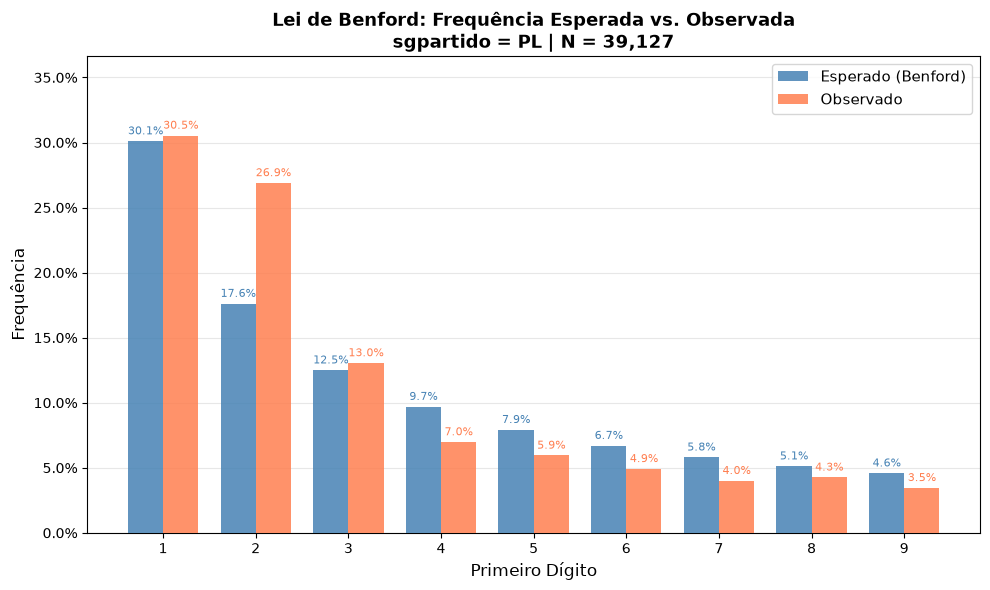

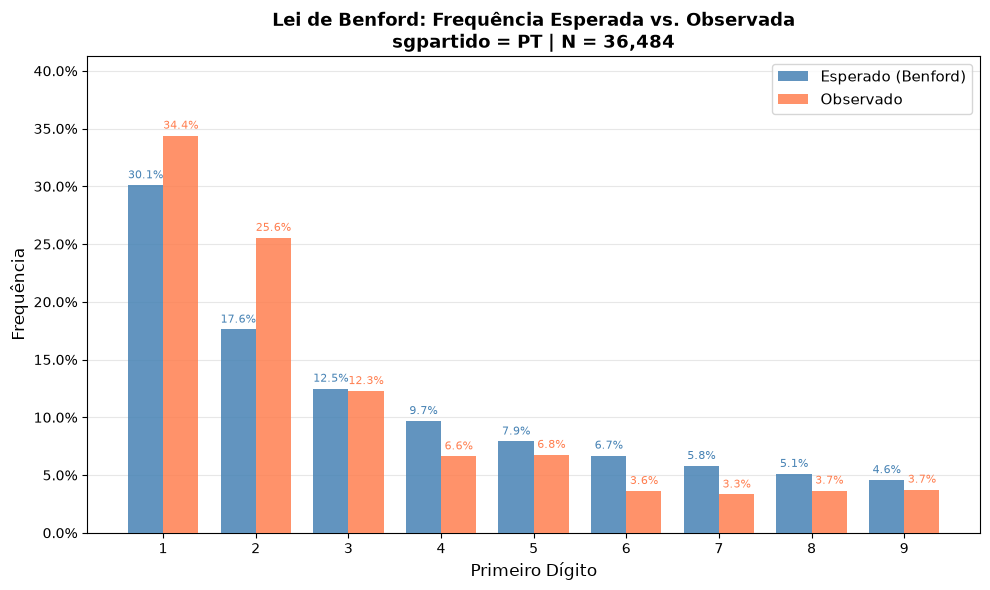

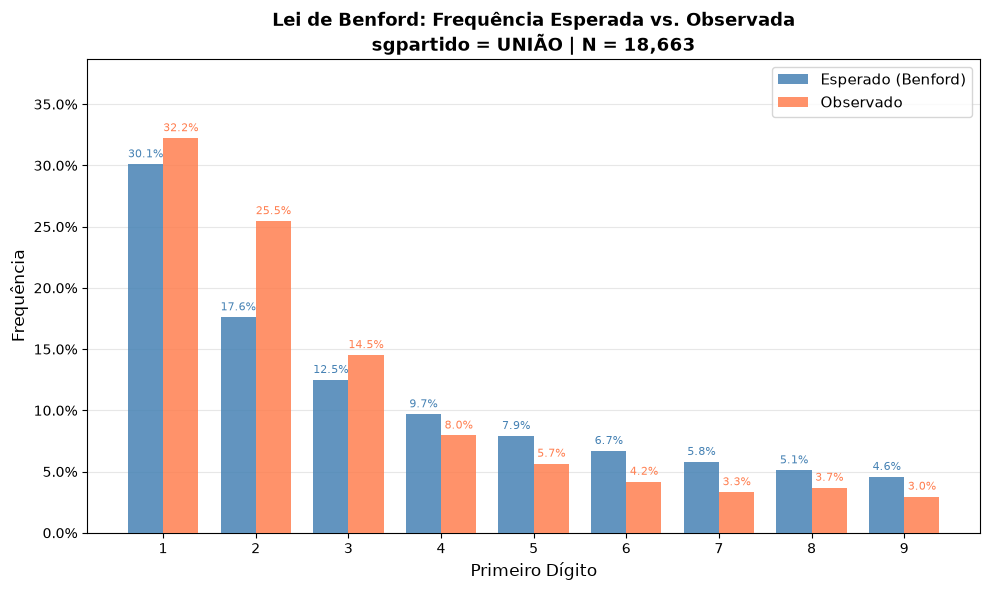

In [90]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.figure import Figure


def plotar_benford(df_benford: pd.DataFrame) -> list[Figure]:
    """Exibe esperado e observado em barras, um gráfico por grupo.

    Recebe o DataFrame retornado por calcular_benford e devolve as figuras
    para permitir salvar os gráficos com fig.savefig(...).
    """
    colunas_resultado = {
        "primeiro_digito", "Benford (%)", "Observado (%)", "Diferença (%)",
        "Observado", "Esperado", "Diferença", "QQ",
    }
    faltantes = colunas_resultado.difference(df_benford.columns)
    if faltantes:
        raise ValueError(f"Colunas ausentes no resultado de Benford: {sorted(faltantes)}")
    if df_benford.empty:
        raise ValueError("O resultado de Benford está vazio; não há dados para o gráfico.")

    colunas_grupo = [c for c in df_benford.columns if c not in colunas_resultado]
    grupos = (
        df_benford.groupby(colunas_grupo, sort=True, dropna=False)
        if colunas_grupo else [((), df_benford)]
    )
    figuras = []
    x = np.array(range(1, 10))
    largura = 0.38

    for chave, grupo in grupos:
        chave = chave if isinstance(chave, tuple) else (chave,)
        grupo = grupo.sort_values("primeiro_digito")
        if grupo["primeiro_digito"].tolist() != list(range(1, 10)):
            raise ValueError("Cada grupo deve conter exatamente uma linha por dígito de 1 a 9.")
        percentuais = grupo[["Benford (%)", "Observado (%)"]]
        if not np.isfinite(percentuais.to_numpy()).all() or not percentuais.ge(0).all().all():
            raise ValueError("As frequências devem ser percentuais finitos e não negativos.")
        n = grupo["Observado"].sum()
        if not np.isfinite(n) or n <= 0:
            raise ValueError("Cada grupo deve ter ao menos uma ocorrência observada.")

        fig, eixo = plt.subplots(figsize=(10, 6))
        barras_esp = eixo.bar(
            x - largura / 2, grupo["Benford (%)"].to_numpy(), largura,
            label="Esperado (Benford)", color="steelblue", alpha=0.85, zorder=3,
        )
        barras_obs = eixo.bar(
            x + largura / 2, grupo["Observado (%)"].to_numpy(), largura,
            label="Observado", color="coral", alpha=0.85, zorder=3,
        )
        for barras, cor in [(barras_esp, "steelblue"), (barras_obs, "coral")]:
            eixo.bar_label(
                barras, labels=[f"{barra.get_height():.1f}%" for barra in barras],
                padding=3, fontsize=8, color=cor,
            )

        entidade = ", ".join(f"{col} = {valor}" for col, valor in zip(colunas_grupo, chave))
        subtitulo = f"{entidade} | N = {n:,.0f}" if entidade else f"N = {n:,.0f}"
        eixo.set_title(
            f"Lei de Benford: Frequência Esperada vs. Observada\n{subtitulo}",
            fontsize=13, fontweight="bold",
        )
        eixo.set_xlabel("Primeiro Dígito", fontsize=12)
        eixo.set_ylabel("Frequência", fontsize=12)
        eixo.set_xticks(x)
        eixo.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
        eixo.legend(fontsize=11)
        eixo.grid(axis="y", alpha=0.3, zorder=0)
        eixo.set_ylim(0, percentuais.max().max() * 1.2)
        fig.tight_layout()
        figuras.append(fig)
        plt.show()

    return figuras


figuras_benford = plotar_benford(df_benford)

In [97]:
prompt_usuario = """
Fazer uma analise de benford para deputados do Pará em Julho e Agosto
"""

response = cliente.models.generate_content(
    model=modelo,
    contents=[prompt_usuario],
    config=types.GenerateContentConfig(
        system_instruction=PROMPT_SISTEMA_GERAR_SQL,
        response_mime_type="application/json",
        response_schema=FORMATO_RESPOSTA_GERAR_SQL,
        **gen_config
    )
)

sql = response.parsed
sql_fmt = sqlparse.format(sql, reindent=True, keyword_case="upper",
                          indent_width=4, strip_whitespace=True)

df_dados = pd.read_sql(sql_fmt, con)

df_benford = calcular_benford(df_dados)
display(qui_quadrado(df_benford))
display(df_benford)

,N,QQ,Crítico,Rejeita Benford
0,561,52.043525,15.507,True


,primeiro_digito,Benford (%),Observado (%),Diferença (%),Observado,Esperado,Diferença,QQ
0,1,30.103000,32.442068,2.339068,182,168.877828,-13.122172,1.019621
1,2,17.609126,26.737968,9.128842,150,98.787196,-51.212804,26.549506
2,3,12.493874,12.655971,0.162098,71,70.090631,-0.909369,0.011798
3,4,9.691001,9.090909,-0.600092,51,54.366517,3.366517,0.208464
4,5,7.918125,5.169340,-2.748784,29,44.420679,15.420679,5.353303
5,6,6.694679,4.099822,-2.594857,23,37.557149,14.557149,5.642350
6,7,5.799195,4.456328,-1.342867,25,32.533482,7.533482,1.744460
7,8,5.115252,2.317291,-2.797962,13,28.696565,15.696565,8.585772
8,9,4.575749,3.030303,-1.545446,17,25.669952,8.669952,2.928251
